# Forming a Concept

*The Mathematics of Machine Intelligence · Chapter 9*

A rule says whether a thing belongs; a summary says how well it fits, and what it keeps depends on the purpose.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the kind is for before choosing a summary. Then choose the matching card: the odd-number ratings to separate a rule from a rating, the prototype and exemplar comparison for averages against stored cases, the weighted distance for feature importance, the category support card for several partial matches, and the bottleneck toy for choosing what a compact code keeps. Report which assumption would change the answer, and test a candidate summary on held-out cases near the boundary.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 9, Forming a Concept: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels(**kwargs):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
ODD_SET_31 = {3: 1.6, 7: 1.9, 23: 2.4, 57: 2.6, 501: 3.5, 447: 3.7}
ODD_SET_21 = {3: 1.0, 447: 1.9}
SAID_NO = {'vehicle': 24, 'vegetable': 33, 'fruit': 43, 'sport': 71, 'female': 86, 'even number': 100, 'odd number': 100, 'plane geometry figure': 100}
RATING_SETS = {'experiment 1': ('Experiment 1: 31 students', ODD_SET_31), 'experiment 3': ('Experiment 3: 21 students', ODD_SET_21)}

def is_odd(n):
    """The membership rule: a whole number is odd when dividing by two leaves a remainder."""
    return n % 2 == 1

def odd_rule_picture(rating_set='experiment 1', kind='odd number'):
    label, ratings = RATING_SETS[rating_set]
    fig, ax = panels()
    order = sorted(ratings, key=lambda n: ratings[n])
    ys = np.arange(len(order))[::-1]
    ax[0].hlines(ys, 1, [ratings[n] for n in order], color=GREY, linewidth=1, alpha=0.6)
    ax[0].plot([ratings[n] for n in order], ys, linestyle='none', marker='o', markersize=9, color=TEAL)
    for n, y in zip(order, ys):
        tag(ax[0], ratings[n] + 0.12, y, f'{ratings[n]:.1f}', ha='left', va='center')
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels([f'{n}  (remainder {n % 2})' for n in order], fontsize=9)
    ax[0].set(xlim=(0.7, 5.2), ylim=(-0.7, len(order) - 0.3), xlabel='mean rating (1 best, 7 worst)', title=label)
    names = list(SAID_NO)
    values = [SAID_NO[k] for k in names]
    colors = [NAVY if k == kind else TERRA if SAID_NO[k] == 100 else TEAL for k in names]
    ypos = np.arange(len(names))[::-1]
    ax[1].barh(ypos, values, color=colors, height=0.62)
    for y, v in zip(ypos, values):
        tag(ax[1], v - 2, y, f'{v}%', ha='right', va='center', color='black')
    ax[1].set_yticks(ypos)
    ax[1].set_yticklabels(names, fontsize=9)
    ax[1].set(xlim=(0, 105), xlabel='percent of 21 who said no', title='Rating by degree makes no sense')
    gap = ratings[447] - ratings[3]
    metrics = {'Rule: remainder of 3 and of 447 on dividing by 2': f'{3 % 2} and {447 % 2}', 'Rating of 3, and of 447 (1 is best)': f'{ratings[3]:.1f} and {ratings[447]:.1f}', 'Gap in mean rating, 447 minus 3': sig(gap), f'Said no to rating for {kind}': f'{SAID_NO[kind]} percent'}
    summary = f"The rule gives 3 and 447 the same answer, remainder 1. Yet {label.split(':')[0].lower()}'s students rated 3 at {ratings[3]:.1f} and 447 at {ratings[447]:.1f}, a gap of {sig(gap)} points on a 7-point scale. For {kind}, {SAID_NO[kind]} percent of a separate group said grading makes no sense."
    calc = f'3 = 2 x 1 + 1 and 447 = 2 x 223 + 1, so both are odd. Mean ratings: {ratings[3]:.1f} for 3 and {ratings[447]:.1f} for 447, so 447 minus 3 = {sig(gap)} rating points. Percent saying no for {kind}: {SAID_NO[kind]}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CASES_A = (2, 3, 4)
CASES_B = (1, 7)
STEP_FACTOR = 3

def prototype_rule(x, cases_a=CASES_A, cases_b=CASES_B):
    """Nearest average. Returns the answer and the two distances."""
    ca, cb = (sum(cases_a) / len(cases_a), sum(cases_b) / len(cases_b))
    da, db = (abs(x - ca), abs(x - cb))
    if abs(da - db) < 1e-12:
        return ('tie', da, db)
    return ('A' if da < db else 'B', da, db)

def exemplar_support(x, cases, factor=STEP_FACTOR):
    return sum((factor ** (-abs(x - c)) for c in cases))

def exemplar_rule(x, cases_a=CASES_A, cases_b=CASES_B, factor=STEP_FACTOR):
    """Total closeness to every stored case. Returns the answer and the two supports."""
    sa, sb = (exemplar_support(x, cases_a, factor), exemplar_support(x, cases_b, factor))
    if abs(sa - sb) < 1e-12:
        return ('tie', sa, sb)
    return ('A' if sa > sb else 'B', sa, sb)

def rule_picture(new_case=0):
    x = float(new_case)
    proto, da, db = prototype_rule(x)
    exem, sa, sb = exemplar_rule(x)
    fig, ax = panels()
    ax[0].hlines(0, -1.5, 8.5, color=GREY, linewidth=1)
    ax[0].plot(CASES_A, [0] * 3, linestyle='none', marker='o', markersize=11, color=TEAL, label='kind A cases')
    ax[0].plot(CASES_B, [0] * 2, linestyle='none', marker='s', markersize=10, color=TERRA, label='kind B cases')
    ax[0].plot([3], [0.45], linestyle='none', marker='D', markersize=10, color=TEAL, markeredgecolor='white')
    ax[0].plot([4], [0.45], linestyle='none', marker='D', markersize=10, color=TERRA, markeredgecolor='white')
    tag(ax[0], 3, 0.8, 'A average 3', fontsize=9, color=TEAL)
    tag(ax[0], 4.35, 0.45, 'B average 4', fontsize=9, color=TERRA, ha='left', va='center')
    ax[0].plot([x], [0], linestyle='none', marker='*', markersize=20, color=GOLD, markeredgecolor=NAVY, zorder=5, label='new case')
    ax[0].set(xlim=(-1.5, 8.5), ylim=(-2.3, 1.2), xlabel='position on the line', title='Cases on a line', yticks=[])
    ax[0].legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=True, handletextpad=0.3, columnspacing=0.8)
    pro_text = {'A': 'A', 'B': 'B', 'tie': 'tie'}[proto]
    exe_text = {'A': 'A', 'B': 'B', 'tie': 'tie'}[exem]
    tag(ax[0], 3.5, -0.75, f'prototype rule: {pro_text}  (distance to A {sig(da)}, to B {sig(db)})', fontsize=8.5, color=NAVY)
    tag(ax[0], 3.5, -1.25, f'exemplar rule: {exe_text}  (support for A {sig(sa)}, for B {sig(sb)})', fontsize=8.5, color=NAVY)
    xs = np.arange(-1.5, 8.5001, 0.05)
    code = {'A': 0, 'B': 1, 'tie': 0.5}
    for row, rule, name in [(1, prototype_rule, 'prototype'), (0, exemplar_rule, 'exemplar')]:
        answers = [rule(float(v))[0] for v in xs]
        for v, a in zip(xs, answers):
            ax[1].fill_between([v - 0.025, v + 0.025], row, row + 0.8, color={'A': TEAL, 'B': TERRA, 'tie': GOLD}[a], linewidth=0)
    disagree = [prototype_rule(float(v))[0] != exemplar_rule(float(v))[0] for v in xs]
    for v, d in zip(xs, disagree):
        if d:
            ax[1].fill_between([v - 0.025, v + 0.025], -0.45, -0.1, color=DARK_GOLD, linewidth=0)
    ax[1].axvline(x, color=NAVY, linewidth=2)
    ax[1].plot([x], [1.4], marker='v', markersize=11, color=NAVY)
    ax[1].set(xlim=(-1.5, 8.5), ylim=(-0.6, 1.75), xlabel='position of the new case', title='Where the rules answer A or B', yticks=[0.4, 1.4, -0.28])
    ax[1].set_yticklabels(['exemplar', 'prototype', 'disagree'], fontsize=9)
    ax[1].grid(False)
    tag(ax[1], 0.2, 1.62, 'teal = A, terracotta = B', fontsize=8, ha='left', va='center')
    agree = 'they disagree' if proto != exem else 'they agree'
    metrics = {'Prototype rule answers': f'{pro_text} (distances {sig(da)} and {sig(db)})', 'Exemplar rule answers': f'{exe_text} (supports {sig(sa)} and {sig(sb)})', 'Do the rules agree?': agree}
    summary = f'A new case at {sig(x)} goes to {pro_text} by the average and to {exe_text} by total closeness to stored cases, so {agree}. The same cases can get two labels, so graded ratings alone cannot say which rule a mind uses.'
    calc = f'Averages: A = (2 + 3 + 4)/3 = 3, B = (1 + 7)/2 = 4. Distances from {sig(x)}: {sig(da)} and {sig(db)}. Support = sum of (1/3)^distance over stored cases: A {sig(sa)}, B {sig(sb)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PROBE = (2.0, 2.0)
CASE_P = (4.0, 2.0)
CASE_Q = (3.0, 4.0)

def weighted_sq_distance(x, z, weights):
    """The chapter's d_w^2: weights nonnegative and adding to one."""
    if min(weights) < 0 or abs(sum(weights) - 1) > 1e-09:
        raise ValueError('Weights must be nonnegative and add up to one.')
    return sum((w * (a - b) ** 2 for w, a, b in zip(weights, x, z)))

def weight_picture(size_weight=0.8):
    w = round(float(size_weight), 6)
    weights = (w, round(1 - w, 6))
    dp = weighted_sq_distance(PROBE, CASE_P, weights)
    dq = weighted_sq_distance(PROBE, CASE_Q, weights)
    nearer = 'P' if dp < dq else 'Q' if dq < dp else 'tie'
    fig, ax = panels()
    gx, gy = np.meshgrid(np.arange(1, 5), np.arange(1, 5))
    ax[0].plot(gx.ravel(), gy.ravel(), linestyle='none', marker='o', markersize=4, color=GREY, alpha=0.5)
    r2 = min(dp, dq)
    if r2 > 0:
        theta = np.linspace(0, 2 * np.pi, 400)
        ax[0].plot(PROBE[0] + math.sqrt(r2 / weights[0]) * np.cos(theta), PROBE[1] + math.sqrt(r2 / weights[1]) * np.sin(theta), color=NAVY, linewidth=1.6, linestyle='dashed', clip_on=True)
    ax[0].plot(*PROBE, marker='*', markersize=18, color=GOLD, markeredgecolor=NAVY, linestyle='none', label='new case', zorder=5)
    ax[0].plot(*CASE_P, marker='o', markersize=12, color=TEAL, linestyle='none', label='stored case P', zorder=5)
    ax[0].plot(*CASE_Q, marker='s', markersize=11, color=TERRA, linestyle='none', label='stored case Q', zorder=5)
    ax[0].set(xlim=(0.3, 5.2), ylim=(0.3, 5.2), xlabel='size (steps)', ylabel='angle (steps)', title='Equal-distance curve through the nearer case')
    ax[0].set_aspect('equal')
    ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    grid = np.linspace(0.02, 0.98, 97)
    ax[1].plot(grid, [weighted_sq_distance(PROBE, CASE_P, (g, 1 - g)) for g in grid], color=TEAL, linewidth=2.2, label='distance to P')
    ax[1].plot(grid, [weighted_sq_distance(PROBE, CASE_Q, (g, 1 - g)) for g in grid], color=TERRA, linewidth=2.2, linestyle='dashed', label='distance to Q')
    ax[1].axvline(4 / 7, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 4 / 7 + 0.015, 3.8, 'swap at 4/7', fontsize=9, color=GREY, ha='left')
    ring(ax[1], w, min(dp, dq))
    ax[1].set(xlabel='weight on size (weight on angle is the rest)', ylabel='squared distance from the new case', title='Which stored case is nearer', ylim=(0, 4.3))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ratio = weights[0] / weights[1]
    metrics = {'Squared distance to P': sig(dp), 'Squared distance to Q': sig(dq), 'Nearer stored case': nearer, 'Size gap counts this many times an equal angle gap': sig(ratio)}
    summary = f'With weights {sig(weights[0])} on size and {sig(weights[1])} on angle, the squared distances are {sig(dp)} to P and {sig(dq)} to Q, so {nearer} is nearer. Changing what counts can change which stored case is nearest.'
    calc = f'Gaps: P differs by 2 in size and 0 in angle, Q by 1 and 2. d^2(P) = {sig(weights[0])} x 4 + {sig(weights[1])} x 0 = {sig(dp)}. d^2(Q) = {sig(weights[0])} x 1 + {sig(weights[1])} x 4 = {sig(dq)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
A_FIRST = 0.6

def category_totals(a_matches, b_matches):
    """Support of each category is the sum of similarities to its stored cases; equal-bias share is each over the sum."""
    sa, sb = (sum(a_matches), sum(b_matches))
    return (sa, sb, sa / (sa + sb))

def verdict(a, b, tol=1e-09):
    return 'tie' if abs(a - b) < tol else 'A' if a > b else 'B'

def support_picture(b_match=0.4, a_second=0.2):
    a_matches = [A_FIRST, a_second]
    sa, sb, share = category_totals(a_matches, [b_match])
    by_total = verdict(sa, sb)
    by_single = verdict(max(a_matches), b_match)
    fig, ax = panels()
    ax[0].bar([0], [A_FIRST], color=TEAL, width=0.55, label='A, first match')
    if a_second > 0:
        ax[0].bar([0], [a_second], bottom=[A_FIRST], color=GOLD, width=0.55, label='A, second match')
    ax[0].bar([1], [b_match], color=TERRA, width=0.55, label='B, one match')
    tag(ax[0], 0, sa + 0.03, f'total {sig(sa)}', va='bottom')
    tag(ax[0], 1, sb + 0.03, f'total {sig(sb)}', va='bottom')
    ax[0].set(xticks=[0, 1], xticklabels=['category A', 'category B'], ylabel='summed similarity', title='Support for each category', ylim=(0, 1.6), xlim=(-0.6, 1.6))
    ax[0].legend(fontsize=8, loc='upper right')
    grid = np.linspace(0.02, 1.0, 99)
    for second, style, colour in [(0.0, 'dotted', GREY), (0.2, 'solid', TEAL), (0.4, 'dashed', TERRA)]:
        chosen = abs(second - a_second) < 1e-09
        ax[1].plot(grid, [category_totals([A_FIRST, second], [g])[2] for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f"A's second match {second:g}")
    ax[1].axhline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    ring(ax[1], b_match, share)
    ax[1].set(xlabel="similarity of B's one match", ylabel="A's share of the total", title="A's share falls as B's match grows", ylim=(0, 1.02))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Total for A': sig(sa), 'Total for B': sig(sb), "A's share": sig(share), 'Winner by total (by best single match)': f'{by_total} ({by_single})'}
    summary = f"A holds {sig(sa)} from its matches and B {sig(sb)}, so A's share is {sig(share)}. By total support the winner is {by_total}; by the single best match it is {by_single}."
    calc = f'A: {A_FIRST:g} + {a_second:g} = {sig(sa)}. B: {b_match:g}. Share of A = {sig(sa)}/({sig(sa)} + {sig(sb)}) = {sig(share)}. This is the equal-bias case, with no response-bias weights.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SUMMARIES = [('keep both', {'shape', 'color'}), ('keep shape only', {'shape'}), ('keep color only', {'color'}), ('keep nothing', set())]

def bottleneck_scores(beta, target):
    """Score = bits kept about the object minus beta times bits kept about the target.

    The object is two independent fair bits (shape, color). A summary keeps whole properties,
    so it keeps one bit about the object per property kept and one bit about the target if it keeps the target."""
    out = {}
    for name, kept in SUMMARIES:
        bits_object = len(kept)
        bits_target = 1 if target in kept else 0
        out[name] = bits_object - beta * bits_target
    return out

def winners(scores, tol=1e-09):
    low = min(scores.values())
    return [k for k, v in scores.items() if v - low < tol]

def bottleneck_picture(target='shape', beta=2):
    scores = bottleneck_scores(beta, target)
    names = [n for n, _ in SUMMARIES]
    best = winners(scores)
    fig, ax = panels()
    ypos = np.arange(len(names))[::-1]
    colors = [NAVY if n in best else GREY for n in names]
    vals = [scores[n] for n in names]
    ax[0].barh(ypos, vals, color=colors, height=0.6)
    ax[0].axvline(0, color='black', linewidth=1)
    spread = max(abs(min(vals)), abs(max(vals)), 1)
    for y, v, n in zip(ypos, vals, names):
        tag(ax[0], v + (0.06 * spread if v >= 0 else -0.06 * spread), y, sig(v), ha='left' if v >= 0 else 'right', va='center')
    ax[0].set_yticks(ypos)
    ax[0].set_yticklabels(names, fontsize=9)
    ax[0].set(xlim=(-spread * 1.35 - 0.2, spread * 1.35 + 0.2), xlabel=f'score (lower wins), target {target}, weight {beta:g}', title='Four summaries scored')
    grid = np.linspace(0, 4, 81)
    styles = {'keep both': (GOLD, 'dashed'), 'keep shape only': (TEAL, 'solid'), 'keep color only': (TERRA, 'dotted'), 'keep nothing': (GREY, 'solid')}
    for n in names:
        colour, style = styles[n]
        ax[1].plot(grid, [bottleneck_scores(g, target)[n] for g in grid], color=colour, linestyle=style, linewidth=2, label=n)
    ring(ax[1], beta, min(scores.values()))
    ax[1].set(xlabel='trade-off weight (beta)', ylabel='score', title=f'Score against the weight, target {target}', ylim=(-3.4, 2.4))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    if len(best) == 1:
        winner_text = best[0]
    else:
        winner_text = ' and '.join(best) + ' (tied)'
    metrics = {'Lowest score': sig(min(scores.values())), 'Winner': winner_text, 'Score of keeping both': sig(scores['keep both']), 'Score of keeping nothing': sig(scores['keep nothing'])}
    summary = f'With target {target} and weight {beta:g}, the lowest score is {sig(min(scores.values()))}, won by {winner_text}. Changing the target or the weight changes the winner, because the purpose decides what is worth keeping.'
    other = 'color' if target == 'shape' else 'shape'
    calc = f"Score = bits about the object - {beta:g} x bits about {target}. Keep both: 2 - {beta:g} x 1 = {sig(scores['keep both'])}. Keep {target} only: 1 - {beta:g} x 1 = {sig(scores['keep ' + target + ' only'])}. Keep {other} only: 1 - 0 = {sig(scores['keep ' + other + ' only'])}. Keep nothing: 0."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
LEVELS = ['superordinate', 'basic', 'subordinate']
LEVEL_EXAMPLE = {'superordinate': 'furniture', 'basic': 'chair', 'subordinate': 'kitchen chair'}
SHARED = {'superordinate': 3.5, 'basic': 9.05, 'subordinate': 11.07}

def level_steps(shared=SHARED):
    """Return (added by each step, share of the whole rise reached at each level)."""
    sup, bas, sub = (shared[k] for k in LEVELS)
    total = sub - sup
    return ({'basic': bas - sup, 'subordinate': sub - bas}, {'superordinate': 0.0, 'basic': (bas - sup) / total, 'subordinate': 1.0})

def level_picture(level='basic'):
    steps, cumulative = level_steps()
    fig, ax = panels()
    colors = [NAVY if k == level else TEAL for k in LEVELS]
    ax[0].bar(range(3), [SHARED[k] for k in LEVELS], color=colors, width=0.62)
    for i, k in enumerate(LEVELS):
        tag(ax[0], i, SHARED[k] + 0.2, f'{SHARED[k]:g}', va='bottom')
    ax[0].set_xticks(range(3))
    ax[0].set_xticklabels([f'{k}\n({LEVEL_EXAMPLE[k]})' for k in LEVELS], fontsize=9)
    ax[0].set(ylabel='shared attributes (average of six taxonomies)', title="Attributes shared by a name's members", ylim=(0, 13.5))
    added = [steps['basic'], steps['subordinate']]
    ax[1].bar([0, 1], added, color=[NAVY if level == 'basic' else TEAL, NAVY if level == 'subordinate' else TEAL], width=0.55)
    for i, v in enumerate(added):
        tag(ax[1], i, v + 0.15, f'+{sig(v)}', va='bottom')
    ax[1].set_xticks([0, 1])
    ax[1].set_xticklabels(['superordinate to basic', 'basic to subordinate'], fontsize=9)
    ax[1].set(ylabel='attributes added by the step', title='The first step adds most', ylim=(0, 7))
    value = SHARED[level]
    if level == 'superordinate':
        gain = 'none (top level)'
    else:
        gain = sig(steps[level])
    metrics = {'Shared attributes at this level': sig(value), 'Added by the step that reaches it': gain, 'Share of the whole rise reached': sig(cumulative[level]), 'Whole rise, top to bottom': sig(SHARED['subordinate'] - SHARED['superordinate'])}
    summary = f"At the {level} level the average is {sig(value)} shared attributes. The first step, from 3.5 to 9.05, adds {sig(steps['basic'])}, which is {sig(cumulative['basic'])} of the whole rise of {sig(SHARED['subordinate'] - SHARED['superordinate'])}. That is why the middle level is called basic."
    calc = f"Rise = 11.07 - 3.5 = {sig(SHARED['subordinate'] - SHARED['superordinate'])}. First step = 9.05 - 3.5 = {sig(steps['basic'])}, and {sig(steps['basic'])}/{sig(SHARED['subordinate'] - SHARED['superordinate'])} = {sig(cumulative['basic'])}. Second step = 11.07 - 9.05 = {sig(steps['subordinate'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C09-D01: Why would students rate 3 as a better odd number than 447?

The rule for odd numbers gives 3 and 447 the same answer. What did students rate instead, and did they think rating made sense?

Both 3 and 447 leave a remainder of 1 when divided by two, so the rule cannot tell them apart. The students still rated 3 as a better example, at 1.6 against 3.7, a gap of 2.1 points. The second group is the surprising part: every one of the 21 said rating odd numbers by degree makes no sense, and still rated 3 at 1.0 and 447 at 1.9.

$$
n \bmod 2 = 1 \ \text{for every odd } n
$$

**Symbols:** n mod 2: the remainder when the whole number n is divided by two; every odd number leaves 1; rating: mean of students' ratings from 1 (a very good example) to 7 (a very poor one)

**Predict before looking:** The rule gives every odd number the same answer. Before opening the second group, predict whether students who said rating makes no sense still graded 3 and 447 differently.

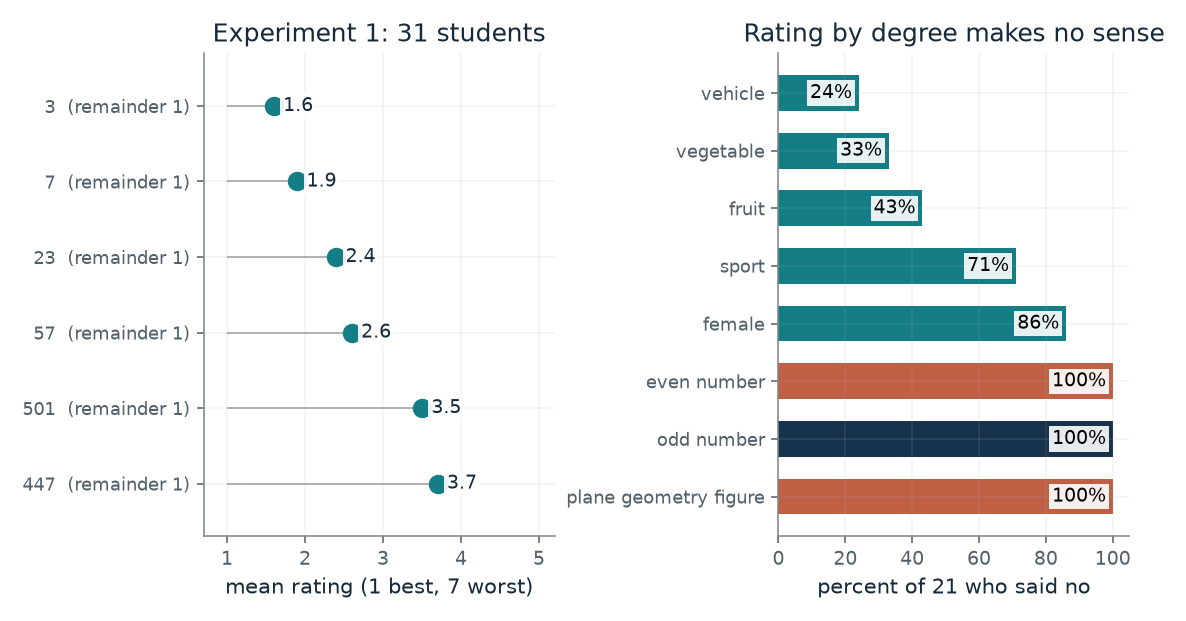

- **Rule: remainder of 3 and of 447 on dividing by 2:** 1 and 1
- **Rating of 3, and of 447 (1 is best):** 1.6 and 3.7
- **Gap in mean rating, 447 minus 3:** 2.1
- **Said no to rating for odd number:** 100 percent

The rule gives 3 and 447 the same answer, remainder 1. Yet experiment 1's students rated 3 at 1.6 and 447 at 3.7, a gap of 2.1 points on a 7-point scale. For odd number, 100 percent of a separate group said grading makes no sense.

3 = 2 x 1 + 1 and 447 = 2 x 223 + 1, so both are odd. Mean ratings: 1.6 for 3 and 3.7 for 447, so 447 minus 3 = 2.1 rating points. Percent saying no for odd number: 100.

In [2]:
figure, values, explanation = odd_rule_picture(**{'rating_set': 'experiment 1', 'kind': 'odd number'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why would students rate 3 as a better odd number than 447?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Group of students = experiment 3, Kind shown on the right = odd number: All 21 students said it makes no sense to rate odd numbers, yet their means still ran from 1.0 for 3 to 1.9 for 447. The grading did not depend on believing the kind was graded.

**Takeaway:** A membership rule asks whether something qualifies; a typicality rating asks how representative it seems. They can give different answers for the same item.

**Why it matters:** A system that applies an exact test and a system that ranks by typicality answer different questions. Treating a good rating as proof of membership, or a flat rule as proof that no ranking exists, mixes them up.

**In brains and behavior:** Students graded an exact kind. The authors suggested a core rule alongside a separate rough identification process; the study did not test why 3 came out ahead, and every result is behavior, not brain activity.

**In machines:** An exact test such as the remainder gives 3 and 447 the same answer. Any graded score a machine reports for them must come from some other computation, such as a summary of cases.

**Where it applies:** The ratings are means of students' judgments of how well a number fits their idea or image of odd. The study measured behavior; it did not test why 3 came out ahead or what a mind stores, and it compared no storage models.

**Check your understanding:** In the chapter's first experiment, how large is the gap in mean rating between 447 and 3, and which of the six odd numbers was rated best after 3?

<details><summary>Show the answer</summary>

447 minus 3 is 3.7 minus 1.6 = 2.1 rating points. After 3 (1.6) the best-rated was 7 at 1.9.

</details>

*Source: Chapter 9, Chapter 9: Forming a Concept. Reported results quoted from the chapter's account of Armstrong, Gleitman and Gleitman (1983): the 31 students' mean ratings of six odd numbers, the 21 students' percentages saying rating by degree makes no sense, and the two Table 6 means for odd number (3 at 1.0, 447 at 1.9). Only those two Table 6 means are given in the chapter.*

## C09-D02: Should a new case be judged by an average or by every stored case?

Kind A has cases at 2, 3 and 4 and kind B at 1 and 7. Where do the two rules disagree about a new case?

The prototype rule keeps only one number per kind. The exemplar rule keeps every case and lets a nearby stored case count a lot. A new case at 0 sits close to B's single case at 1, so the exemplar rule favors B even though A's average is nearer. Moving the new case along the line shows two stretches where the rules answer differently.

$$
\text{prototype: nearest average},\qquad \text{exemplar: } S_K(x)=\sum_{c\in K}\left(\tfrac13\right)^{|x-c|}
$$

**Symbols:** x: the position of the new case on the line; c: a stored case of kind K; S_K(x): the exemplar support for kind K: each stored case counts a third as much for each step of distance

**Predict before looking:** A new case at 0 is far from both averages (3 and 4). Predict which kind each rule picks.

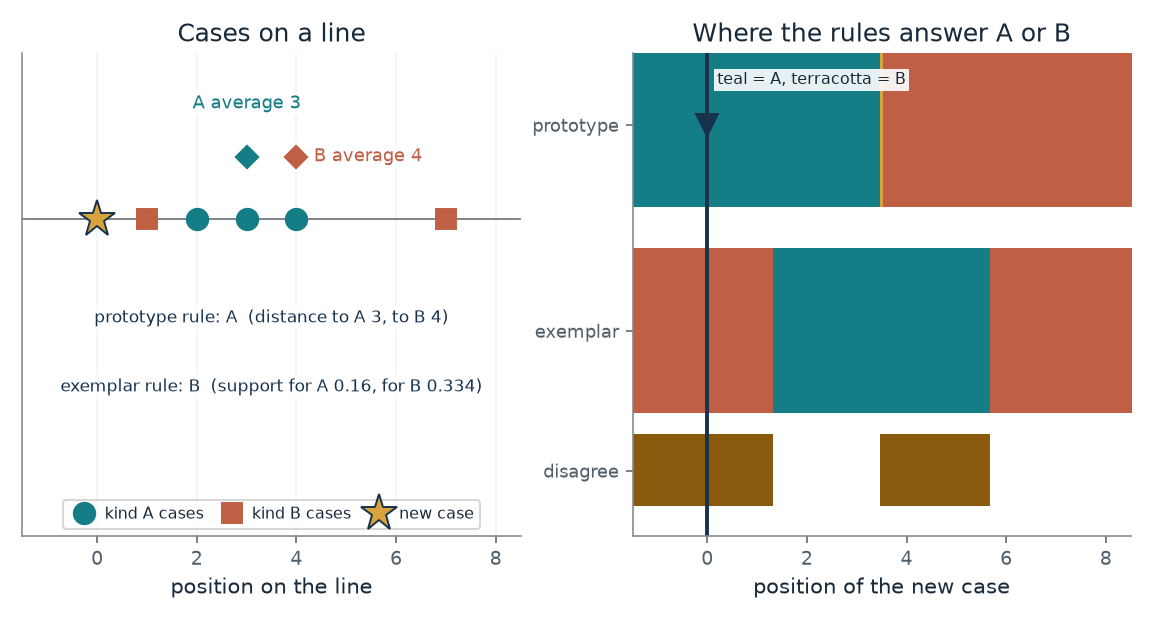

- **Prototype rule answers:** A (distances 3 and 4)
- **Exemplar rule answers:** B (supports 0.16 and 0.334)
- **Do the rules agree?:** they disagree

A new case at 0 goes to A by the average and to B by total closeness to stored cases, so they disagree. The same cases can get two labels, so graded ratings alone cannot say which rule a mind uses.

Averages: A = (2 + 3 + 4)/3 = 3, B = (1 + 7)/2 = 4. Distances from 0: 3 and 4. Support = sum of (1/3)^distance over stored cases: A 0.16, B 0.334.

In [3]:
figure, values, explanation = rule_picture(**{'new_case': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Should a new case be judged by an average or by every stored case?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Position of the new case = 0: At 0 the average of A (3) is nearer than the average of B (4), so the prototype rule says A. The exemplar rule says B: its case at 1 is one step away and counts about 0.33, against about 0.16 in total from A's three cases.

**Takeaway:** The same stored cases can give two different labels, so graded ratings alone cannot say which rule a mind uses.

**Why it matters:** Few-shot machine classifiers that label a new input by its nearest class average use the first rule; a system that compares with every stored case uses the second. Knowing which one is in use predicts where it will disagree with the other.

**In brains and behavior:** Whether a mind keeps one average or each case is open. Graded ratings fit a prototype account but do not prove one, and the odd-number studies compared no storage models.

**In machines:** In prototypical networks (Snell and colleagues, 2017) a class's prototype is the average of its embedded cases and a new input goes to the nearest one. The word is borrowed from psychology and the authors do not claim to model human concepts.

**Where it applies:** One line, two kinds with fixed cases. The prototype rule uses the plain average; the exemplar rule adds closeness over every stored case with a fixed one-third decay. Real studies of people compared no storage models.

**Check your understanding:** For a new case at 5, which kind does the prototype rule pick, and which does the exemplar rule pick?

<details><summary>Show the answer</summary>

Distances to the averages are 2 (A at 3) and 1 (B at 4), so the prototype rule says B. The exemplar support is (1/3)^3 + (1/3)^2 + (1/3)^1 = 0.481 for A and (1/3)^4 + (1/3)^2 = 0.123 for B, so the exemplar rule says A.

</details>

*Source: Chapter 9, Would a rating make sense for odd numbers? Twenty-one students said no. The chapter's constructed example (not data): cases at 2, 3, 4 and 1, 7, a new case at 0, and a stored case counting a third as much for each step. The sweep over other positions is the companion's own use of the same two rules.*

## C09-D03: How does a feature weight change which stored case is nearest?

A new case differs from stored case P mostly in size and from stored case Q mostly in angle. Which is nearer as the weight on size changes?

Each feature's gap is squared, scaled by its weight and added. P differs only in size, so its distance is 4 times the size weight. Q differs a little in size and a lot in angle, so its distance shrinks as the angle weight falls. At small size weights P is nearer; once size dominates, Q is.

$$
d_w^2(x,z)=\sum_k w_k\,(x_k-z_k)^2,\quad \sum_k w_k=1,\quad w_k\ge 0
$$

**Symbols:** d_w^2(x,z): the weighted squared distance between cases x and z; k: a feature; here size and angle; w_k: the weight on feature k, nonnegative, all weights add to one; x_k, z_k: the two cases' values on feature k

**Predict before looking:** P is 2 steps off in size only. Q is 1 step off in size and 2 in angle. Predict whether the weight on size must be above or below one half for P to be nearer.

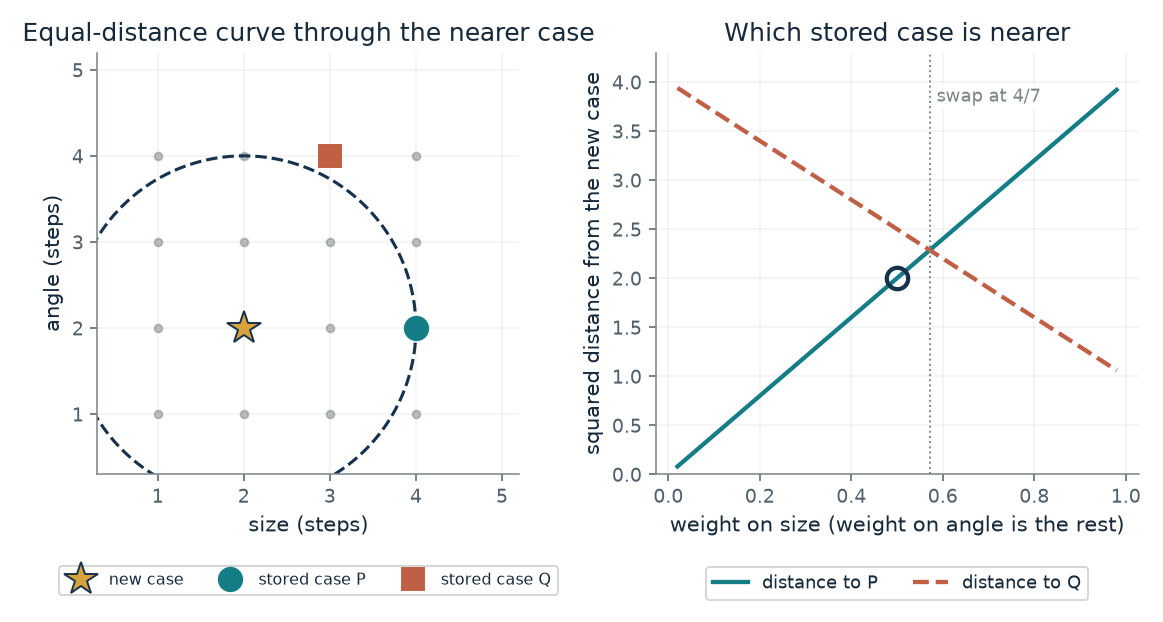

- **Squared distance to P:** 2
- **Squared distance to Q:** 2.5
- **Nearer stored case:** P
- **Size gap counts this many times an equal angle gap:** 1

With weights 0.5 on size and 0.5 on angle, the squared distances are 2 to P and 2.5 to Q, so P is nearer. Changing what counts can change which stored case is nearest.

Gaps: P differs by 2 in size and 0 in angle, Q by 1 and 2. d^2(P) = 0.5 x 4 + 0.5 x 0 = 2. d^2(Q) = 0.5 x 1 + 0.5 x 4 = 2.5.

In [4]:
figure, values, explanation = weight_picture(**{'size_weight': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a feature weight change which stored case is nearest?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on size = 0.8: At weights 0.8 and 0.2 a size gap counts four times an equal angle gap, as in the chapter. P then scores 3.2 and Q only 1.6, so Q is nearer. The swap is at a size weight of 4/7, about 0.571.

**Takeaway:** What counts as alike depends on how much each feature is weighted, so the nearest stored case can change when the weights change.

**Why it matters:** A distance with fixed weights bakes in a view of which features matter. Changing the purpose can change the weights and with them the answer.

**In brains and behavior:** In the semicircle study the fitted weights followed the task: where size alone decided the kind, the weight on angle fell to nearly zero. That is a model fitted to choices of two paid observers.

**In machines:** A task weight over features is fixed for a task. Transformer attention, by contrast, is worked out afresh for each input, so the machine parallel is only partial.

**Where it applies:** Two features, weights adding to one. The cases are made up. The weights in Nosofsky's study were estimated from choices; attention was never manipulated, so they describe a pattern without showing a cause.

**Check your understanding:** With a size weight of 0.5, what are the squared distances to P and to Q?

<details><summary>Show the answer</summary>

d^2(P) = 0.5 x 4 + 0.5 x 0 = 2. d^2(Q) = 0.5 x 1 + 0.5 x 4 = 2.5. P is nearer.

</details>

*Source: Chapter 9, Sixteen semicircles, and weights that followed the task. The chapter's weighted-distance equation. The positions (new case at 2, 2; P at 4, 2; Q at 3, 4 on a four-by-four grid like the 16 semicircles) are constructed by the companion; they are not Nosofsky's stimuli or data.*

## C09-D04: Can a category win without any single decisive match?

Category A has matches of 0.6 and a second one; category B has a single match. How does a category's share come out, and when does the total disagree with the best single match?

Each category's support is the sum of the similarities to its stored cases, and dividing by the sum over both gives a share. With two partial matches A reaches 0.8 and B's single 0.4 gives it only a third of the total. Raising B's match to 0.8 ties the totals. At 0.7, B owns the best single match, but A's two matches still add to more.

$$
\text{support}(K)=\sum_{c\in K}s(c),\qquad P(A)=\frac{\text{support}(A)}{\text{support}(A)+\text{support}(B)}
$$

**Symbols:** s(c): the similarity of the new case to stored case c; support(K): a category's total similarity over its stored cases; P(A): A's share of the total, when no category is given extra bias

**Predict before looking:** A has 0.6 and 0.2 and B has 0.4. Predict how large B's single match must be before A's share falls to one half.

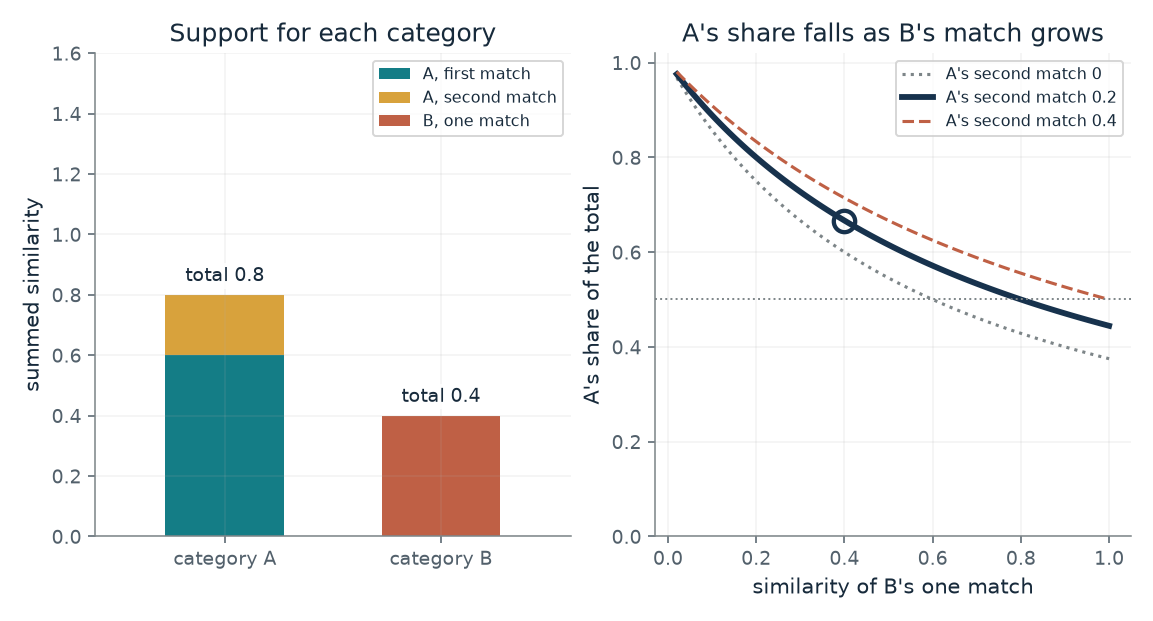

- **Total for A:** 0.8
- **Total for B:** 0.4
- **A's share:** 0.667
- **Winner by total (by best single match):** A (A)

A holds 0.8 from its matches and B 0.4, so A's share is 0.667. By total support the winner is A; by the single best match it is A.

A: 0.6 + 0.2 = 0.8. B: 0.4. Share of A = 0.8/(0.8 + 0.4) = 0.667. This is the equal-bias case, with no response-bias weights.

In [5]:
figure, values, explanation = support_picture(**{'b_match': 0.4, 'a_second': 0.2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a category win without any single decisive match?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Similarity of B's one match = 0.7, Similarity of A's second match = 0.2: B's match of 0.7 is higher than any single match of A (0.6), yet A's total of 0.8 still wins, with a share of 0.533. A category can win through several partial matches even when no single case is decisive.

**Takeaway:** Adding similarities over every stored case can pick a different category from the single best match.

**Why it matters:** A rule that reads only the single closest case and a rule that sums over all cases behave differently near a boundary. Which one a system uses decides how it treats one strong lookalike against several moderate ones.

**In brains and behavior:** The semicircle model fit well, accounting for between about three quarters and nearly all of the pattern in the choices. It is a fitted model of two observers' behavior.

**In machines:** A system that sums similarity over stored cases is computing this rule as a specification; whether a given trained model does so internally is a separate question.

**Where it applies:** Equal response bias for the two categories, as in the chapter. The similarities are chosen by hand and no data stand behind them.

**Check your understanding:** With A's matches 0.6 and 0.2, what share does A hold when B's one match is 0.8?

<details><summary>Show the answer</summary>

A's total is 0.8, B's is 0.8, and A's share is 0.8/(0.8 + 0.8) = 1/2.

</details>

*Source: Chapter 9, Sixteen semicircles, and weights that followed the task. The chapter's constructed example: A has partial matches of 0.6 and 0.2, B has one of 0.4, and A's share is about 0.67. The practice question (B rising to 0.8 gives a share of 1/2) is in the book's back matter. Other values are the companion's own variation.*

## C09-D05: What should a compact summary keep: shape or color?

An object has a shape bit and a color bit. Which of four summaries scores lowest when the target is shape, and what happens if the target or the trade-off weight changes?

Each summary pays one point per bit it keeps about the object and earns beta points per bit it keeps about the target. With a large enough weight, keeping the target wins. With weight 0 the target earns nothing, so keeping nothing wins. At weight 1 keeping shape and keeping nothing tie, and the rule alone does not choose between them.

$$
\min_T\; I(X;T)-\beta\,I(T;Y)
$$

**Symbols:** X: the input, here the object with its shape bit and color bit; T: the summary; its cost is the bits it keeps about X; Y: the target, the signal the summary must predict (shape or color); beta: the trade-off weight, zero or more, chosen first

**Predict before looking:** At weight 2 and target shape, predict the lowest score and which summary reaches it. Then predict what happens at weight 0.

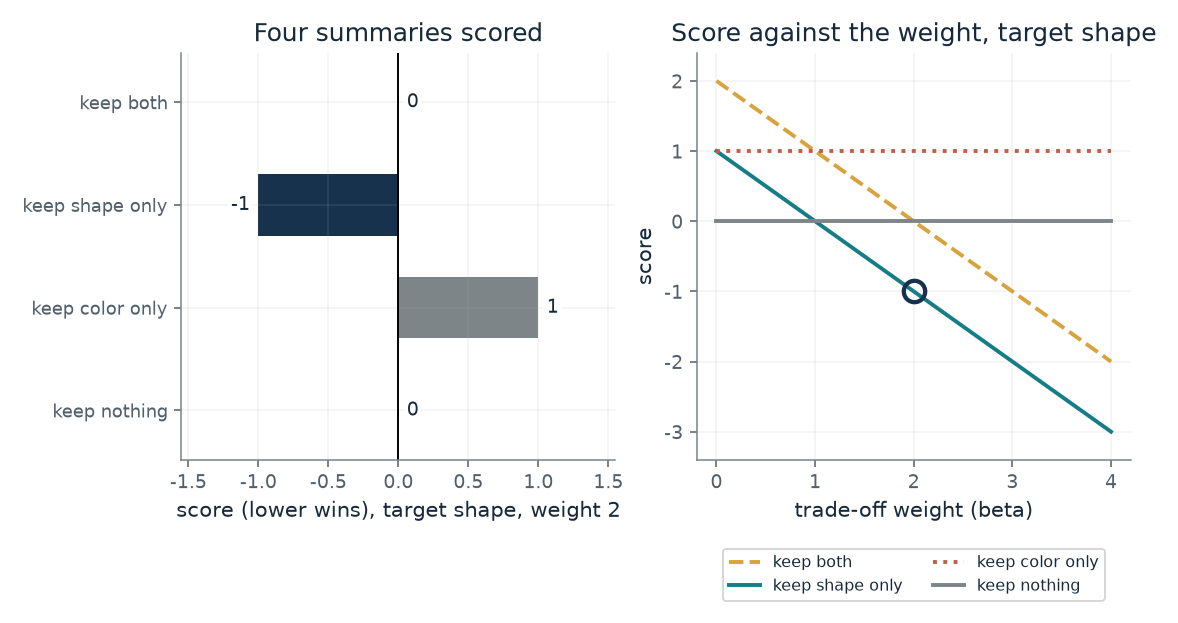

- **Lowest score:** -1
- **Winner:** keep shape only
- **Score of keeping both:** 0
- **Score of keeping nothing:** 0

With target shape and weight 2, the lowest score is -1, won by keep shape only. Changing the target or the weight changes the winner, because the purpose decides what is worth keeping.

Score = bits about the object - 2 x bits about shape. Keep both: 2 - 2 x 1 = 0. Keep shape only: 1 - 2 x 1 = -1. Keep color only: 1 - 0 = 1. Keep nothing: 0.

In [6]:
figure, values, explanation = bottleneck_picture(**{'target': 'shape', 'beta': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What should a compact summary keep: shape or color?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Target = shape, Trade-off weight (beta) = 2: Keeping shape only scores 1 - 2 = -1, below keeping both (0), color only (1) and nothing (0). No summary can score below -1 at this weight, since shape carries one bit and keeping shape reaches that bound.

**Takeaway:** A summary is good for a purpose, and the purpose is the target: change it and the winner changes.

**Why it matters:** A compact code that keeps color and drops a faint marking can score well on average and still miss the cases that matter. Someone has to name the purpose before the summary can be judged.

**In brains and behavior:** The toy does not explain the odd-number ratings and the bottleneck paper has no brain evidence. It is a way to say what a concept keeps, not a claim about what a mind keeps.

**In machines:** A designer or user has to decide what the system should preserve. In the toy the chosen purpose decides the winner.

**Where it applies:** A summary keeps whole properties. Each property is one independent fair bit. The target is named before the summary is chosen, and the weight is set by hand; the paper itself says there is no single right solution for the trade-off.

**Check your understanding:** Target shape, weight 1. Which summaries tie for the lowest score?

<details><summary>Show the answer</summary>

Scores are 1 (both), 0 (shape only), 1 (color only) and 0 (nothing), so shape only and nothing tie at 0.

</details>

*Source: Chapter 9, A toy summary that keeps shape and drops color. The chapter's constructed example (not data): two independent fair bits, four summaries and a weight set by hand to 2. The practice questions (weights 0 and 1) are the same toy at other weights. The paper behind the idea (Tishby, Pereira and Bialek) contains no data and no shape-and-color case.*

## C09-D06: Why is the middle level of a name called basic?

Students listed attributes for names at three levels. Which step adds the most shared attributes?

Going from the broad name to the middle name adds 5.55 shared attributes. Going on to the most specific name adds only 2.02 more. The specific name still has the highest total, which is why the basic level is chosen by the size of the jump and not by the largest count.

$$
\text{share of the rise}=\frac{A_{\text{basic}}-A_{\text{super}}}{A_{\text{sub}}-A_{\text{super}}}
$$

**Symbols:** A_super, A_basic, A_sub: average shared attributes at the superordinate, basic and subordinate levels: 3.5, 9.05 and 11.07

**Predict before looking:** The most specific level holds the most shared attributes. Predict what share of the whole rise comes in the first step, from the broad name to the middle name.

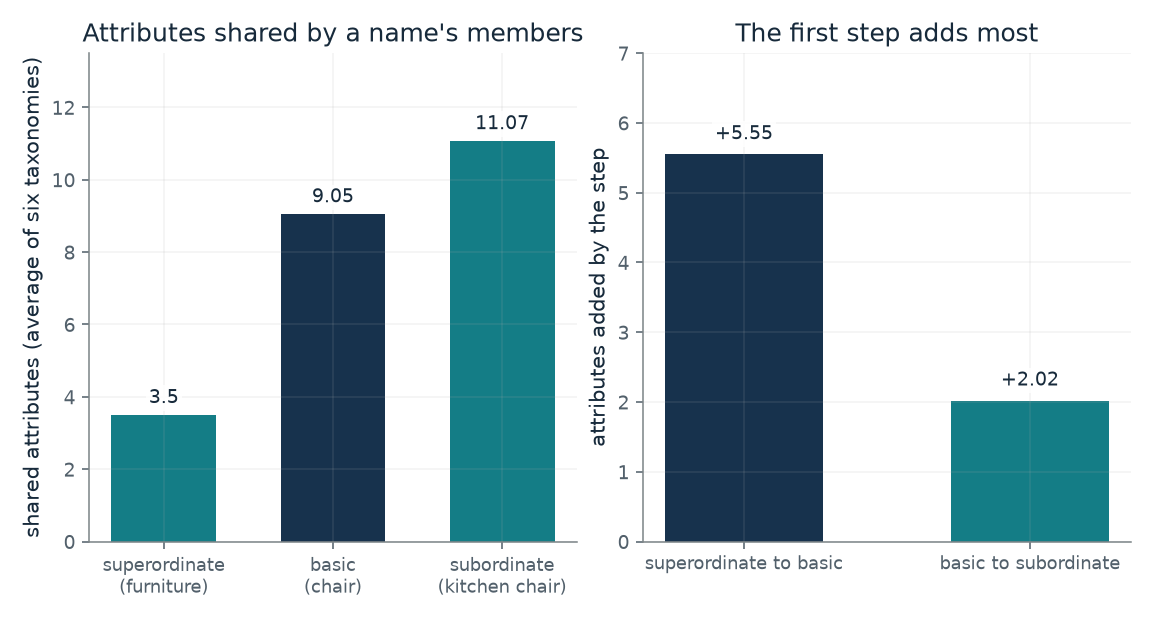

- **Shared attributes at this level:** 9.05
- **Added by the step that reaches it:** 5.55
- **Share of the whole rise reached:** 0.733
- **Whole rise, top to bottom:** 7.57

At the basic level the average is 9.05 shared attributes. The first step, from 3.5 to 9.05, adds 5.55, which is 0.733 of the whole rise of 7.57. That is why the middle level is called basic.

Rise = 11.07 - 3.5 = 7.57. First step = 9.05 - 3.5 = 5.55, and 5.55/7.57 = 0.733. Second step = 11.07 - 9.05 = 2.02.

In [7]:
figure, values, explanation = level_picture(**{'level': 'basic'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why is the middle level of a name called basic?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Level = basic: The first step adds 5.55 of the whole 7.57, about 0.73, roughly three quarters. The second step adds only 2.02. The biggest jump comes at the middle level.

**Takeaway:** The middle level is basic because the largest gain in shared attributes comes there, even though the most specific level holds the most in total.

**Why it matters:** A name that buys a lot of shared structure at a small cost is useful for a mind or a system that must label things cheaply. Counting where the gain is largest, not where the total is largest, picks that level.

**In brains and behavior:** The students' lists are behavior. The chapter notes a related result on color words in 111 languages scored against a best possible trade-off, but the paper does not show that speakers compute a trade-off.

**In machines:** A system with a bottleneck cost could look for the level where one label buys the most for its cost. That is the chapter's interpretation, not a result of the study.

**Where it applies:** The counts are attributes listed by at least six of 20 students. The study counted attributes; it fit no trade-off to these counts, and reading the middle level as a good trade is the chapter's interpretation, not the paper's.

**Check your understanding:** What share of the whole rise from 3.5 to 11.07 happens in the first step?

<details><summary>Show the answer</summary>

The whole rise is 11.07 - 3.5 = 7.57, the first step is 9.05 - 3.5 = 5.55, and 5.55/7.57 = 0.733.

</details>

*Source: Chapter 9, Names favor a middle level, and color words sat near a best trade-off. Reported result, quoted from the chapter's account of Rosch and colleagues (1976): 200 students, 90 object names in nine taxonomies. The averages 3.5, 9.05 and 11.07 are the book's averages of the paper's raw tallies over six taxonomies (trees, fish and birds left out), not figures printed in the paper. The ratios computed here are the companion's arithmetic on them.*

## Bring it to your own question

Ask what the kind is for before choosing a summary. Then choose the matching card: the odd-number ratings to separate a rule from a rating, the prototype and exemplar comparison for averages against stored cases, the weighted distance for feature importance, the category support card for several partial matches, and the bottleneck toy for choosing what a compact code keeps. Report which assumption would change the answer, and test a candidate summary on held-out cases near the boundary.

Use the `mmi-ch09-forming-concept` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.